In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", None)

chunks = []

ALIAS_CANDIDATES = "/home/user/branes/NER-data/entity_candidates_alias.csv"
NO_MATCH_CANDIDATES = "/home/user/branes/NER-data/entity_candidates_no_match.csv"

df_alias = pd.read_csv(ALIAS_CANDIDATES)
df_no_match = pd.read_csv(NO_MATCH_CANDIDATES)

df_alias.head()


,doc_id,doc_year,text,score,start,end,label,text_norm,golden_match,exact_match,fuzzy_candidate,query_context,matched_title,matched_year,rerank_score,top_k_matches
0,A/RES/77/76,2022,Treaty on the Non-Proliferation of Nuclear Weapons,0.999807,5705,5756,INSTRUMENT,treaty on the non-proliferation of nuclear weapons,Treaty on the Non-Proliferation of Nuclear Weapons,True,NaN,"ast of the 1995 Review and Extension Conference of the Parties to the NPT5 and the\n\n__________________\n\n4 2010 Review Conference of the Parties to the[ Treaty on the Non-Proliferation of Nuclear Weapons], Final Document, vols. I–III (NPT/CONF.2010/50 (Vol. I), NPT/CONF.2010/50 (Vol. II) and NPT/CONF.2010/50 (Vol. III)). 5 See 1995 Review and Extension",Treaty on the Non-Proliferation of Nuclear Weapons,1968,-3.7500,"[{'title': 'Treaty on the Non-Proliferation of Nuclear Weapons', 'year': 1968, 'score': -3.75}, {'title': 'International Atomic Energy Treaty', 'year': 1957, 'score': -6.28125}, {'title': 'Basic Principles and Guidelines on the Right to a Remedy and Reparation for Victims of Gross Violations of International Human Rights Law and Serious Violations of International Humanitarian Law', 'year': 2005, 'score': -6.375}, {'title': 'International Convention for the Suppression of Acts of Nuclear Terrorism', 'year': 2005, 'score': -6.5625}, {'title': 'Additional Protocol to the Convention on Prohibitions or Restrictions on the Use of Certain Conventional Weapons which may be deemed to be Excessively Injurious or to have Indiscriminate Effects (Protocol IV, entitled Protocol on Blinding Laser Weapons)', 'year': 1995, 'score': -6.5625}]"
1,52/28,1997,united nations convention on the law of the sea,0.997639,777,825,INSTRUMENT,united nations convention on the law of the sea,United Nations Convention on the Law of the Sea,True,NaN,"tocks, and resolutions 50/24 of 5 december 1995 and 51/35 of 9 december 1996, concerning the agreement for the implementation of the provisions of the[ united nations convention on the law of the sea] of 10 december 1982 relating to the conservation and management of straddling fish stocks and highly migratory fish stocks,1 recalling also resolutio",Agreement for the Implementation of the Provisions of the United Nations Convention on the Law of the Sea of 10 December 1982 relating to the Conservation and Management of Straddling Fish Stocks and Highly Migratory Fish Stocks,1995,6.7500,"[{'title': 'Agreement for the Implementation of the Provisions of the United Nations Convention on the Law of the Sea of 10 December 1982 relating to the Conservation and Management of Straddling Fish Stocks and Highly Migratory Fish Stocks', 'year': 1995, 'score': 6.75}, {'title': 'Agreement relating to the implementation of Part XI of the United Nations Convention on the Law of the Sea of 10 December 1982', 'year': 1994, 'score': 5.125}, {'title': 'United Nations Convention on the Law of the Sea', 'year': 1982, 'score': 3.125}, {'title': 'Convention on Fishing and Conservation of the Living Resources of the High Seas', 'year': 1958, 'score': 2.25}, {'title': 'United Nations Convention on the Law of the Sea', 'year': 1994, 'score': -0.625}]"
2,61/74,2006,comprehensive nuclear-test-ban treaty,0.999886,5386,5424,INSTRUMENT,comprehensive nuclear-test-ban treaty,Comprehensive Nuclear-Test-Ban Treaty,True,NaN,"ernational stability and based on the principle of undiminished security for all; 9. urges all states that have not yet done so to sign and ratify the[ comprehensive nuclear-test-ban treaty] 6 at the earliest opportunity with a view to its early entry into force, stresses the importance of maintaining existing moratoriums on nuclear-weapo",Partial Nuclear Test Ban Treaty,1963,0.7500,"[{'title': 'Partial Nuclear Test Ban Treaty', 'year': 1963, 'score': 0.75}, {'title': 'Comprehensive Nuclear-Test-Ban Treaty', 'year': 1996, 'score': 0.625}, {'title': 'Comprehensive Nuclear-Test-Ban Treaty', 'year': 1996, 'score': 0.625}, {'title': 'Threshold Test 

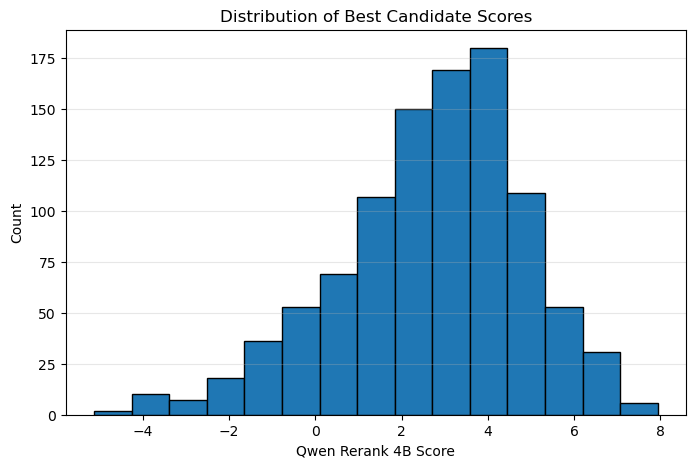

In [2]:
plt.figure(figsize=(8, 5))
plt.hist(df_alias["rerank_score"].dropna(), bins=15, edgecolor="black")
plt.xlabel("Qwen Rerank 4B Score")
plt.ylabel("Count")
plt.title("Distribution of Best Candidate Scores")
plt.grid(axis="y", alpha=0.3)
plt.show()

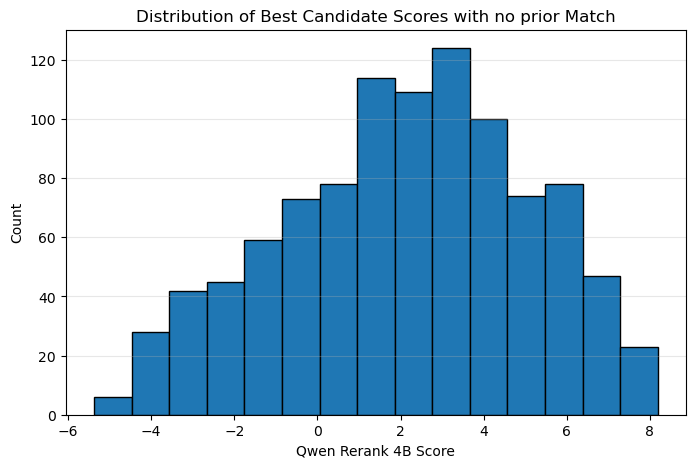

In [3]:
plt.figure(figsize=(8, 5))
plt.hist(df_no_match["rerank_score"].dropna(), bins=15, edgecolor="black")
plt.xlabel("Qwen Rerank 4B Score")
plt.ylabel("Count")
plt.title("Distribution of Best Candidate Scores with no prior Match")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [4]:
df_alias[df_alias["rerank_score"]>7].head()

,doc_id,doc_year,text,score,start,end,label,text_norm,golden_match,exact_match,fuzzy_candidate,query_context,matched_title,matched_year,rerank_score,top_k_matches
73,66/288,2012,united nations framework convention on climate change,0.999654,10126,10180,INSTRUMENT,united nations framework convention on climate change,United Nations Framework Convention on Climate Change,True,NaN,"the three rio conventions for advancing sustainable development, and in this regard we urge all parties to fully implement their commitments under the[ united nations framework convention on climate change], 23 the convention on biological diversity 24 and the united nations convention to combat desertification in those countries experiencing serious dro","Rio Conventions (United Nations Framework Convention on Climate Change, Convention on Biological Diversity, United Nations Convention to Combat Desertification)",1992,7.6250,"[{'title': 'Rio Conventions (United Nations Framework Convention on Climate Change, Convention on Biological Diversity, United Nations Convention to Combat Desertification)', 'year': 1992, 'score': 7.625}, {'title': 'United Nations Convention to Combat Desertification in those Countries Experiencing Serious Drought and/or Desertification, Particularly in Africa', 'year': 1994, 'score': 3.375}, {'title': 'United Nations Framework Convention on Climate Change', 'year': 1992, 'score': 1.625}, {'title': 'United Nations Framework Convention on Climate Change', 'year': 1992, 'score': 1.625}, {'title': 'Rotterdam Convention on the Prior Informed Consent Procedure for Certain Hazardous Chemicals and Pesticides in International Trade', 'year': 1998, 'score': 1.25}]"
485,63/42,2008,"convention on the prohibition of the use, stockpiling, production and transfer of anti-personnel mines and on their destruction",0.999848,1492,1620,INSTRUMENT,"convention on the prohibition of the use, stockpiling, production and transfer of anti-personnel mines and on their destruction","Convention on the Prohibition of the Use, Stockpiling, Production and Transfer of Anti-Personnel Mines and on their Destruction",True,NaN,"the care and rehabilitation, including the social and economic reintegration, of mine victims, welcoming the entry into force, on 1 march 1999, of the[ convention on the prohibition of the use, stockpiling, production and transfer of anti-personnel mines and on their destruction], 1 and noting with satisfaction the work undertaken 0f to implement the convention and the substantial progress made towards addressing the global an","Convention on the Prohibition of the Use, Stockpiling, Production and Transfer of Anti-Personnel Mines and on their Destruction",1997,7.0625,"[{'title': 'Convention on the Prohibition of the Use, Stockpiling, Production and Transfer of Anti-Personnel Mines and on their Destruction', 'year': 1997, 'score': 7.0625}, {'title': 'Ottawa Treaty', 'year': 1997, 'score': 4.25}, {'title': 'Protocol on Prohibitions or Restrictions on the Use of Mines, Booby-Traps and Other Devices as amended on 3 May 1996 (Protocol II, as amended on 3 May 1996) annexed to the Convention on Prohibitions or Restrictions on the Use of Certain Conventional Weapons which may be deemed to be Excessively Injurious or to have Indiscriminate Effects', 'year': 1996, 'score': -1.9375}, {'title': 'Home Work Convention, 1996 (No. 177)', 'year': 1996, 'score': -2.125}, {'title': 'Bishkek Protocol', 'year': 1994, 'score': -2.4375}]"
674,A/RES/76/207,2021,United Nations Convention to Combat Desertification,0.810337,23886,23938,INSTRUMENT,united nations convention to combat desertification,United Nations Convention to Combat Desertification,True,NaN,"eting to promote a coherent approach between the United Nations Framework Convention on Climate Change, the Convention on Biological Diversity and the[ United Nations Convention to Combat Desertification] in Those Countries Experiencing Serious Drought and/or Desertification, Particularly in Africa36 (the Rio co